# PIC 院内死亡预测：课程作业分析
本分析承接教师的6特征示例，增加统计推断、交叉验证、缺失指示变量、
随机森林、概率校准检查及bootstrap置信区间。
主分析读取不含ID的教学Excel；扩展分析用已逐行核对的上游CSV评价患者分组。
将data.xlsx放在本目录或data/目录。也可设置环境变量PIC_DATA_PATH指定路径。

In [1]:
import hashlib
import itertools
import json
import os
import platform
import warnings
from importlib import metadata
from pathlib import Path

import joblib
import matplotlib
NOTEBOOK_MODE = "get_ipython" in globals() and get_ipython() is not None
if not NOTEBOOK_MODE:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from scipy.special import logit
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, confusion_matrix, f1_score, precision_recall_curve,
    roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
ROOT = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
for directory in ["tables", "figures", "models", "results"]:
    (ROOT / directory).mkdir(exist_ok=True)
FEATURES = ["age_month", "lab_5237_min", "lab_5227_min", "lab_5225_range", "lab_5235_max", "lab_5257_min"]
TARGET = "HOSPITAL_EXPIRE_FLAG"
COLORS = ["#9aa5b1", "#0e7490", "#dc6b3a", "#147d64", "#7c559b"]
SHORT = {"Dummy": "无信息基线", "LR": "普通LR", "LR_balanced": "平衡权重LR", "LR_missing": "LR + 缺失指示", "RF_missing": "随机森林 + 缺失指示"}
COLORS.append("#9a5816")
SHORT["RF_plain"] = "随机森林（无指示）"
sns.set_theme(style="whitegrid", font="Microsoft YaHei", rc={"axes.unicode_minus": False})
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False, "axes.spines.right": False})
versions = {name: metadata.version(name) for name in ["pandas", "numpy", "scipy", "scikit-learn", "statsmodels", "matplotlib", "seaborn", "shap", "joblib", "nbformat", "nbclient", "ipykernel", "openpyxl"]}
print("Python", platform.python_version())
display(pd.Series(versions, name="version").to_frame())

def save_table(frame, name):
    frame.to_csv(ROOT / "tables" / f"{name}.csv", index=False, encoding="utf-8-sig")
    return frame

def show_figure(name):
    plt.savefig(ROOT / "figures" / f"{name}.png", bbox_inches="tight")
    plt.savefig(ROOT / "figures" / f"{name}.pdf", bbox_inches="tight")
    if NOTEBOOK_MODE:
        plt.show()
    plt.close("all")

def ptext(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"

Python 3.12.14


,version
pandas,2.3.3
numpy,2.5.4
scipy,1.16.3
scikit-learn,1.7.2
statsmodels,0.14.5
matplotlib,3.10.7
seaborn,0.13.2
shap,0.48.0
joblib,1.5.2
nbformat,5.10.4


## 1. 读取、结构核对与标签
读取Excel而非原始PIC数据库；不推测lab编号的临床名称。
文件校验值用于区分数据版本。保留原始表，固定清理规则作用于副本。

In [2]:
candidates = [Path(os.environ["PIC_DATA_PATH"])] if os.environ.get("PIC_DATA_PATH") else [ROOT / "data.xlsx", ROOT / "data" / "data.xlsx", Path.home() / "Downloads" / "data.xlsx"]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("请将data.xlsx放在项目目录，或设置PIC_DATA_PATH。")
raw_data = pd.read_excel(DATA_PATH)
assert raw_data.columns.tolist() == FEATURES + [TARGET], "数据字段与教学版本不匹配。"
assert raw_data[TARGET].notna().all() and raw_data[TARGET].isin([0, 1]).all()
data = raw_data.copy()
invalid_age = data["age_month"] < 0
data.loc[invalid_age, "age_month"] = np.nan
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("数据形状", data.shape, "SHA256", data_sha256)
# 公开版省略逐行原始记录展示；本地课程版保留。
outcome = raw_data[TARGET].value_counts().sort_index().rename_axis("label").reset_index(name="n")
outcome["proportion"] = outcome["n"] / len(data)
display(save_table(outcome, "outcomes"))
qc = pd.DataFrame({"feature": FEATURES, "missing_raw": raw_data[FEATURES].isna().sum().values, "missing_cleaned": data[FEATURES].isna().sum().values, "missing_rate": data[FEATURES].isna().mean().values, "unique_observed": data[FEATURES].nunique().values, "min_observed": data[FEATURES].min().values, "max_observed": data[FEATURES].max().values})
display(save_table(qc, "data_quality"))
lab_columns = FEATURES[1:]
all_lab_missing = data[lab_columns].isna().all(axis=1)
audit = {
    "n": len(data), "deaths": int(data[TARGET].sum()), "mortality": float(data[TARGET].mean()),
    "negative_age": int(invalid_age.sum()), "age_over_216": int((raw_data.age_month > 216).sum()),
    "identical_rows_beyond_first": int(raw_data.duplicated().sum()),
    "all_labs_missing": int(all_lab_missing.sum()),
    "complete_cases_after_age_cleaning": int(data[FEATURES].notna().all(axis=1).sum()),
    "complete_case_deaths": int(data.loc[data[FEATURES].notna().all(axis=1), TARGET].sum()),
    "patient_id_available": False, "time_window_verifiable": False,
}
display(pd.Series(audit).to_frame("value"))
print("相同特征不证明同一患者，不自动删除重复行。月龄0保留；217个月保留并做敏感性分析。")

## 2. 固定训练/测试集
按标签分层80/20划分，seed=42，与教师示例保持一致。
数据无患者ID，无法实施患者分组；这一限制不由删除相同特征解决。
图示和Table 1仅用于描述，任何模型设计、调参和阈值选择只使用训练集。

In [3]:
X = data[FEATURES].copy()
y = data[TARGET].astype(int)
train_index, test_index = train_test_split(data.index.to_numpy(), test_size=0.20, random_state=SEED, stratify=y)
X_train, X_test = X.loc[train_index], X.loc[test_index]
y_train, y_test = y.loc[train_index], y.loc[test_index]
split_table = pd.DataFrame({"split": ["train", "test"], "n": [len(y_train), len(y_test)], "deaths": [int(y_train.sum()), int(y_test.sum())], "mortality": [y_train.mean(), y_test.mean()]})
display(save_table(split_table, "data_split"))
split_membership = pd.DataFrame({"source_row_index": data.index, "split": np.where(data.index.isin(train_index), "train", "test")})
split_membership.to_csv(ROOT / "results" / "split_membership_private.csv", index=False)
assert set(train_index).isdisjoint(test_index)

,split,n,deaths,mortality
0,train,10606,624,0.058835
1,test,2652,156,0.058824


## 3. 缺失、分布与相关性
缺失率按结局描述，不据此选择特征。相关系数使用成对完整观测，样本量不完全相同。

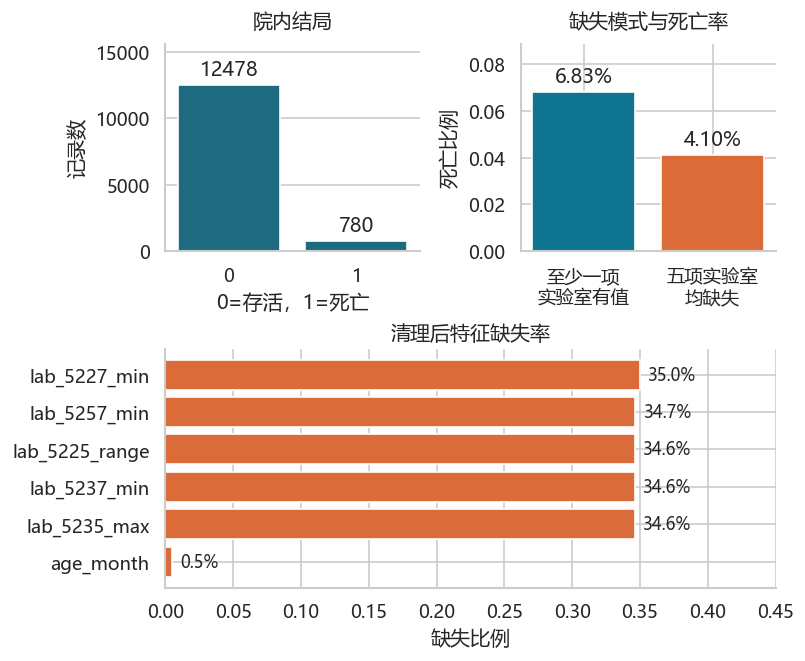

,feature,missing_survived,missing_died
0,age_month,0.005289,0.002564
1,lab_5237_min,0.352781,0.241026
2,lab_5227_min,0.356788,0.243590
3,lab_5225_range,0.352941,0.241026
4,lab_5235_max,0.352540,0.241026
5,lab_5257_min,0.353101,0.243590


HOSPITAL_EXPIRE_FLAG,all_labs_missing,0,1,mortality
0,至少一项实验室有值,8079,592,0.068274
1,五项实验室全缺失,4399,188,0.040985


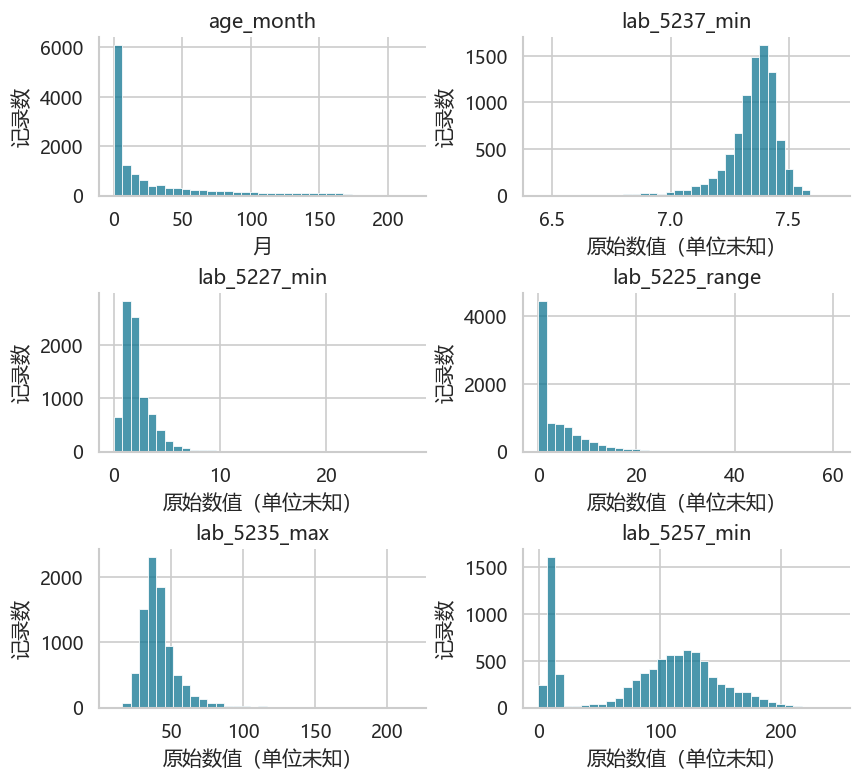

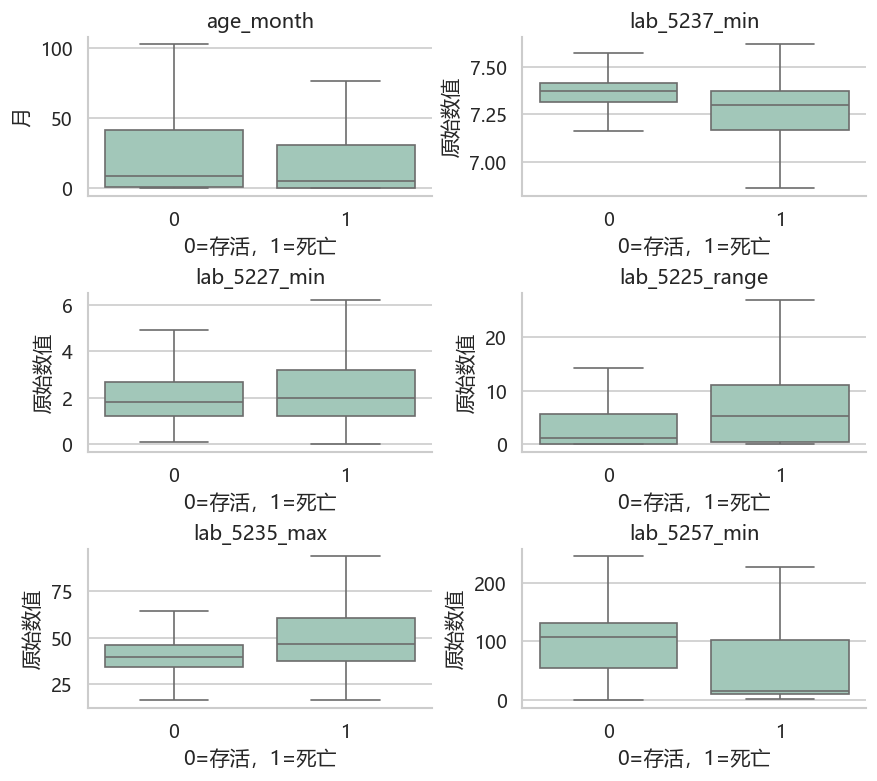

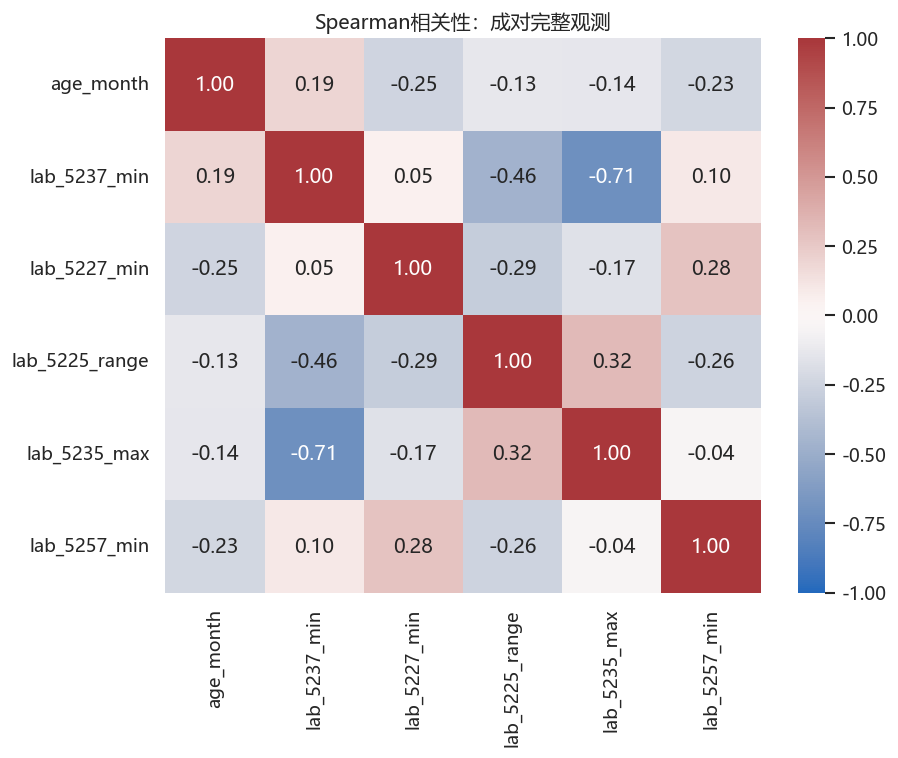

In [4]:
fig = plt.figure(figsize=(6.6, 5.4), layout="constrained")
grid = fig.add_gridspec(2, 2, height_ratios=[1, 1.15])
axes = [fig.add_subplot(grid[0, 0]), fig.add_subplot(grid[1, :]), fig.add_subplot(grid[0, 1])]
sns.countplot(data=data, x=TARGET, color=COLORS[1], ax=axes[0])
axes[0].set(xlabel="0=存活，1=死亡", ylabel="记录数", ylim=(0, 1.25 * data[TARGET].value_counts().max()))
axes[0].set_title("院内结局", pad=10)
axes[0].bar_label(axes[0].containers[0], fmt="%d", padding=3)
missing_sorted = data[FEATURES].isna().mean().sort_values()
axes[1].barh(missing_sorted.index, missing_sorted.values, color=COLORS[2])
axes[1].set(title="清理后特征缺失率", xlabel="缺失比例", xlim=(0, .45))
for i, v in enumerate(missing_sorted): axes[1].text(v+.006, i, f"{v:.1%}", va="center", fontsize=10)
pattern = pd.crosstab(all_lab_missing, y).rename(index={False: "至少一项实验室有值", True: "五项实验室全缺失"})
pattern["mortality"] = pattern[1] / (pattern[0] + pattern[1])
axes[2].bar(["至少一项\n实验室有值", "五项实验室\n均缺失"], pattern["mortality"], color=[COLORS[1], COLORS[2]])
axes[2].set(ylabel="死亡比例", ylim=(0, 1.30 * pattern["mortality"].max()))
axes[2].set_title("缺失模式与死亡率", pad=10)
axes[2].bar_label(axes[2].containers[0], labels=[f"{v:.2%}" for v in pattern["mortality"]], padding=3)
show_figure("01_data_quality")
missing_group = data[FEATURES].isna().groupby(y).mean().T.reset_index(names="feature")
missing_group.columns = ["feature", "missing_survived", "missing_died"]
display(save_table(missing_group, "missing_by_outcome"))
display(save_table(pattern.reset_index(names="all_labs_missing"), "missing_patterns"))

fig, axes = plt.subplots(3, 2, figsize=(7.2, 6.4), constrained_layout=True)
for column, ax in zip(FEATURES, axes.flat):
    sns.histplot(data=data, x=column, bins=35, color=COLORS[1], ax=ax)
    ax.set(title=column, xlabel="月" if column == "age_month" else "原始数值（单位未知）", ylabel="记录数")
show_figure("02_distributions")
fig, axes = plt.subplots(3, 2, figsize=(7.2, 6.4), constrained_layout=True)
for column, ax in zip(FEATURES, axes.flat):
    sns.boxplot(data=data, x=TARGET, y=column, showfliers=False, color="#9ccdbb", ax=ax)
    ax.set(title=column, xlabel="0=存活，1=死亡", ylabel="月" if column == "age_month" else "原始数值")
show_figure("03_outcome_boxplots")
corr = data[FEATURES].corr(method="spearman")
save_table(corr.reset_index(names="feature"), "spearman_correlation")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman相关性：成对完整观测")
show_figure("04_correlation")

## 4. 统计分析：Table 1、效应量与FDR
六个变量统一使用中位数[IQR]和双侧Mann-Whitney U检验。
缺失值不插补后用于组间检验；每个变量给出实际观测数。
SMD = (死亡组均值-存活组均值)/两组方差均值的平方根。
rank-biserial r为方向性秩效应量。六项检验用Benjamini-Hochberg校正。

In [5]:
table1_rows = []
for column in FEATURES:
    a = data.loc[y == 0, column].dropna()
    b = data.loc[y == 1, column].dropna()
    u, p = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled_sd = np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    def describe(s):
        return f"{s.median():.3g} [{s.quantile(.25):.3g}, {s.quantile(.75):.3g}]"
    table1_rows.append({"feature": column, "overall_median_IQR": describe(data[column].dropna()), "survived_median_IQR": describe(a), "died_median_IQR": describe(b), "n_survived_observed": len(a), "n_died_observed": len(b), "missing_survived": int(((y == 0) & data[column].isna()).sum()), "missing_died": int(((y == 1) & data[column].isna()).sum()), "SMD_death_minus_survival": (b.mean()-a.mean())/pooled_sd, "rank_biserial": 2*u/(len(a)*len(b))-1, "p": p})
table1 = pd.DataFrame(table1_rows)
table1["q_BH"] = multipletests(table1.p, method="fdr_bh")[1]
display(save_table(table1, "table1"))

miss_tests = []
for column in FEATURES:
    counts = pd.crosstab(data[column].isna(), y).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    odds, p = stats.fisher_exact(counts.to_numpy())
    miss_tests.append({"feature": column, "fisher_p": p, "missing_death_odds_ratio": odds})
missing_tests = pd.DataFrame(miss_tests)
missing_tests["q_BH"] = multipletests(missing_tests.fisher_p, method="fdr_bh")[1]
display(save_table(missing_tests, "missingness_tests"))

,feature,overall_median_IQR,survived_median_IQR,died_median_IQR,n_survived_observed,n_died_observed,missing_survived,missing_died,SMD_death_minus_survival,rank_biserial,p,q_BH
0,age_month,"8 [1, 42]","9 [1, 42]","5 [0, 31]",12412,778,66,2,-0.059894,-0.080918,1.368842e-04,1.642611e-04
1,lab_5237_min,"7.37 [7.31, 7.42]","7.37 [7.31, 7.42]","7.3 [7.16, 7.37]",8076,592,4402,188,-0.690304,-0.377747,2.799368e-53,8.398103e-53
2,lab_5227_min,"1.8 [1.2, 2.7]","1.8 [1.2, 2.7]","2 [1.2, 3.2]",8026,590,4452,190,0.241323,0.082660,7.854408e-04,7.854408e-04
3,lab_5225_range,"1.5 [0, 6]","1.2 [0, 5.7]","5.2 [0.475, 11.1]",8074,592,4404,188,0.540791,0.310687,9.688109e-40,1.937622e-39
4,lab_5235_max,"39.6 [34.2, 46.9]","39.3 [34, 46.1]","46.4 [37.1, 60.4]",8079,592,4399,188,0.527729,0.308034,5.132931e-36,7.699397e-36
5,lab_5257_min,"105 [17.6, 131]","107 [55, 132]","15.2 [9.4, 103]",8072,590,4406,190,-0.676871,-0.378954,1.909670e-53,8.398103e-53


,feature,fisher_p,missing_death_odds_ratio,q_BH
0,age_month,4.381103e-01,0.483446,4.381103e-01
1,lab_5237_min,7.746891e-11,0.582616,1.167857e-10
2,lab_5227_min,5.141587e-11,0.580558,1.167857e-10
3,lab_5225_range,7.755609e-11,0.582207,1.167857e-10
4,lab_5235_max,7.785715e-11,0.583230,1.167857e-10
5,lab_5257_min,1.735349e-10,0.589981,2.082419e-10


## 5. 探索性关联回归
与预测模型分开：不加类别权重、不正则化。
单因素用每项非缺失记录；多因素用六项均完整的记录。
OR均对应增加一个IQR，单因素取变量的非缺失记录，多因素取完整记录。
完整病例分析可能有选择偏倚；CI基于记录独立的假设，不能解释为因果效应。

,analysis,feature,unit_IQR,n,OR,CI_low,CI_high,p,q_BH_within_analysis
0,univariable,age_month,41.000,13190,0.942647,0.873771,1.016951,1.270717e-01,1.270717e-01
1,multivariable_complete_case,age_month,36.000,8539,0.956970,0.881117,1.039353,2.965432e-01,2.965432e-01
2,univariable,lab_5237_min,0.109,8668,0.587709,0.551047,0.626810,7.738147e-59,4.642888e-58
3,multivariable_complete_case,lab_5237_min,0.108,8539,0.771927,0.694678,0.857765,1.495359e-06,2.990718e-06
4,univariable,lab_5227_min,1.500,8616,1.186953,1.127520,1.249519,6.182170e-11,7.418605e-11
5,multivariable_complete_case,lab_5227_min,1.500,8539,1.079227,1.011417,1.151583,2.128707e-02,3.193060e-02
6,univariable,lab_5225_range,6.000,8666,1.637794,1.528813,1.754543,8.558599e-45,1.711720e-44
7,multivariable_complete_case,lab_5225_range,6.000,8539,1.261121,1.166127,1.363853,6.384076e-09,1.915223e-08
8,univariable,lab_5235_max,12.700,8671,1.403226,1.323190,1.488103,1.225511e-29,1.838267e-29
9,multivariable_complete_case,lab_5235_max,12.800,8539,1.098664,1.010200,1.194875,2.802811e-02,3.363374e-02


,feature,VIF
0,age_month,1.037447
1,lab_5237_min,2.765403
2,lab_5227_min,1.206512
3,lab_5225_range,1.315531
4,lab_5235_max,2.251953
5,lab_5257_min,1.075226


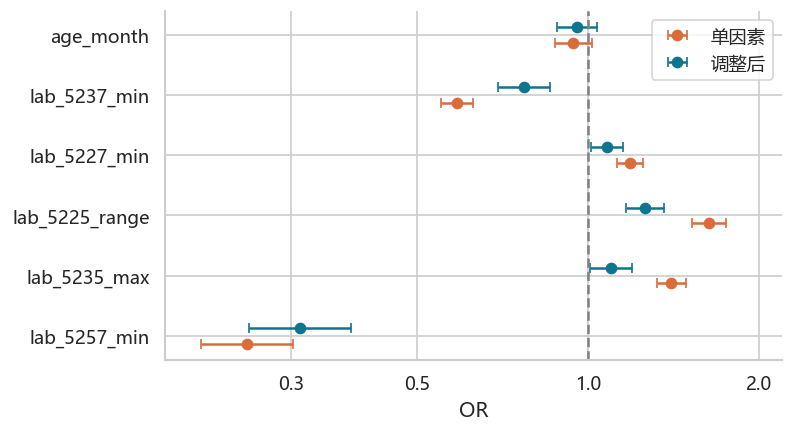

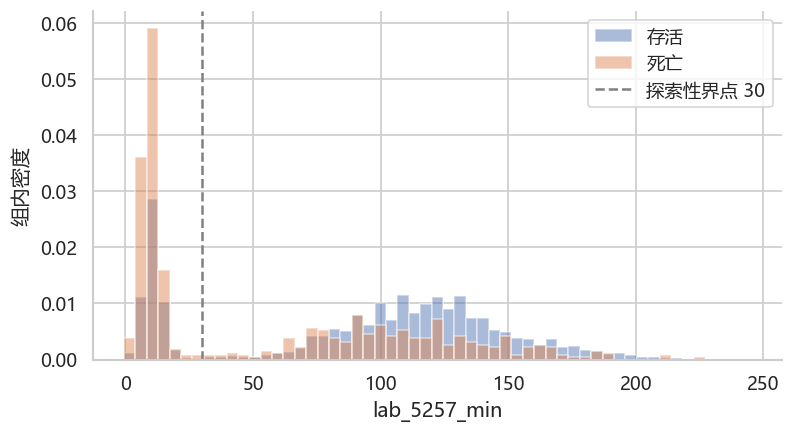

In [6]:
complete = data.dropna(subset=FEATURES).copy()
iqr_scale = complete[FEATURES].quantile(.75) - complete[FEATURES].quantile(.25)
assert (iqr_scale > 0).all()
scaled_complete = (complete[FEATURES] - complete[FEATURES].median()) / iqr_scale
multivariable = sm.Logit(complete[TARGET], sm.add_constant(scaled_complete)).fit(disp=False, cov_type="HC0")
reg_rows = []
for column in FEATURES:
    observed = data[[column, TARGET]].dropna()
    observed_iqr = observed[column].quantile(.75) - observed[column].quantile(.25)
    z = (observed[[column]] - observed[column].median()) / observed_iqr
    uni = sm.Logit(observed[TARGET], sm.add_constant(z)).fit(disp=False, cov_type="HC0")
    for kind, fit, n in [("univariable", uni, len(observed)), ("multivariable_complete_case", multivariable, len(complete))]:
        low, high = fit.conf_int().loc[column]
        reg_rows.append({"analysis": kind, "feature": column, "unit_IQR": float(observed_iqr if kind == "univariable" else iqr_scale[column]), "n": n, "OR": np.exp(fit.params[column]), "CI_low": np.exp(low), "CI_high": np.exp(high), "p": fit.pvalues[column]})
regression = pd.DataFrame(reg_rows)
regression["q_BH_within_analysis"] = regression.groupby("analysis")["p"].transform(lambda ps: multipletests(ps, method="fdr_bh")[1])
display(save_table(regression, "association_OR"))
vif_design = sm.add_constant(scaled_complete)
vif = pd.DataFrame({"feature": FEATURES, "VIF": [variance_inflation_factor(vif_design.to_numpy(), i+1) for i in range(len(FEATURES))]})
display(save_table(vif, "VIF"))
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
for kind, offset, label, color in [("univariable", -.13, "单因素", COLORS[2]), ("multivariable_complete_case", .13, "调整后", COLORS[1])]:
    forest = regression[regression.analysis == kind].iloc[::-1]
    ax.errorbar(forest.OR, np.arange(len(forest)) + offset, xerr=[forest.OR-forest.CI_low, forest.CI_high-forest.OR], fmt="o", color=color, capsize=3, label=label)
ax.set_yticks(np.arange(len(forest)), forest.feature)
ax.axvline(1, color="gray", ls="--")
ax.set(xscale="log", xlabel="OR", xlim=(.18, 2.2))
ax.set_xticks([.3, .5, 1, 2], labels=["0.3", "0.5", "1.0", "2.0"])
ax.minorticks_off()
ax.legend()
show_figure("05_OR_forest")

age_labels = ["≤1", "(1, 12]", "(12, 36]", "(36, 120]", ">120"]
age_groups = pd.cut(data.age_month, [-np.inf, 1, 12, 36, 120, np.inf], labels=age_labels)
age_rates = data.groupby(age_groups.rename("age_group"), observed=True)[TARGET].agg(n="size", deaths="sum").reset_index()
age_rates["mortality"] = age_rates.deaths / age_rates.n
save_table(age_rates, "age_group_mortality")
age_dummies = pd.get_dummies(age_groups.loc[complete.index], dtype=float)
age_design = pd.concat([age_dummies.drop(columns=["(36, 120]"]), scaled_complete.drop(columns=["age_month"])], axis=1)
age_fit = sm.Logit(complete[TARGET], sm.add_constant(age_design)).fit(disp=False, cov_type="HC0")
age_ci = age_fit.conf_int()
age_terms = age_dummies.columns.drop("(36, 120]")
save_table(pd.DataFrame({"age_group": age_terms, "reference": "(36, 120]", "n": len(complete), "OR": np.exp(age_fit.params.loc[age_terms]), "CI_low": np.exp(age_ci.loc[age_terms, 0]), "CI_high": np.exp(age_ci.loc[age_terms, 1])}), "age_group_adjusted_OR")
lab = data[["lab_5257_min", TARGET]].dropna()
lab_summary = lab.groupby(lab.lab_5257_min.lt(30).rename("below_30"))[TARGET].agg(n="size", deaths="sum").reset_index()
lab_summary["mortality"] = lab_summary.deaths / lab_summary.n
lab_summary["fraction"] = lab_summary.n / len(lab)
save_table(lab_summary, "lab_5257_low_cluster")
save_table(lab.lab_5257_min.quantile([.05, .25, .5]).rename("value").rename_axis("quantile").reset_index(), "lab_5257_quantiles")
fig, ax = plt.subplots(figsize=(6.5, 3.5), layout="constrained")
edges = np.histogram_bin_edges(lab.lab_5257_min, bins=55)
for label, group in lab.groupby(TARGET):
    ax.hist(group.lab_5257_min, bins=edges, density=True, alpha=.48, label=["存活", "死亡"][label])
ax.axvline(30, color="gray", ls="--", label="探索性界点 30")
ax.set(xlabel="lab_5257_min", ylabel="组内密度")
ax.legend()
show_figure("12_lab_5257_distribution")

## 6. 模型与训练集交叉验证
保留示例的Dummy、普通LR、平衡LR；新增缺失指示LR和随机森林。
所有插补和标准化均位于Pipeline内。普通/平衡LR固定C=1以复现参考；
LR_missing在C∈{0.1,1,10}中搜索；RF在深度{5,None}和叶节点最小样本{5,20}中搜索。
所有搜索用同一训练集5折分层CV，按AP选择参数和主模型。
表中CV结果参与了参数选择，存在选择乐观性；最终性能由留出测试集评价。

In [7]:
def lr_pipeline(balanced=False, indicator=False):
    return Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=indicator)), ("scaler", StandardScaler()), ("classifier", LogisticRegression(class_weight="balanced" if balanced else None, C=1.0, max_iter=2000, random_state=SEED))])

models = {
    "Dummy": Pipeline([("imputer", SimpleImputer(strategy="median")), ("classifier", DummyClassifier(strategy="prior"))]),
    "LR": lr_pipeline(),
    "LR_balanced": lr_pipeline(balanced=True),
    "LR_missing": lr_pipeline(indicator=True),
    "RF_missing": Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("classifier", RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=20, random_state=SEED, n_jobs=2))]),
}
grids = {
    "Dummy": {}, "LR": {}, "LR_balanced": {},
    "LR_missing": {"classifier__C": [0.1, 1.0, 10.0]},
    "RF_missing": {"classifier__max_depth": [5, None], "classifier__min_samples_leaf": [5, 20]},
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fitted, searches, cv_rows = {}, {}, []
for name, model in models.items():
    print("训练/CV:", name, flush=True)
    search = GridSearchCV(model, grids[name], scoring={"AP": "average_precision", "AUROC": "roc_auc", "neg_Brier": "neg_brier_score"}, refit="AP", cv=cv5, n_jobs=1, return_train_score=False, error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search
    fitted[name] = search.best_estimator_
    i = search.best_index_
    cv_rows.append({"model": name, "CV_AP_mean": search.cv_results_["mean_test_AP"][i], "CV_AP_sd": search.cv_results_["std_test_AP"][i], "CV_AUROC_mean": search.cv_results_["mean_test_AUROC"][i], "CV_Brier_mean": -search.cv_results_["mean_test_neg_Brier"][i], "best_params": json.dumps(search.best_params_)})
    save_table(pd.DataFrame(search.cv_results_).drop(columns=[c for c in search.cv_results_ if c.startswith("param_")]), f"grid_{name}")
cv_results = pd.DataFrame(cv_rows)
display(save_table(cv_results, "CV_model_comparison"))
best_name = cv_results[cv_results.model != "Dummy"].sort_values("CV_AP_mean", ascending=False).iloc[0]["model"]
print("按训练CV AP锁定主模型:", best_name)
rf_plain = clone(fitted["RF_missing"]).set_params(imputer__add_indicator=False)
ablation = GridSearchCV(rf_plain, {}, scoring={"AP": "average_precision", "AUROC": "roc_auc", "neg_Brier": "neg_brier_score"}, refit="AP", cv=cv5, error_score="raise").fit(X_train, y_train)
fitted["RF_plain"] = ablation.best_estimator_
scores = ablation.cv_results_
cv_results = pd.concat([cv_results, pd.DataFrame([{
    "model": "RF_plain", "CV_AP_mean": scores["mean_test_AP"][0], "CV_AP_sd": scores["std_test_AP"][0],
    "CV_AUROC_mean": scores["mean_test_AUROC"][0], "CV_Brier_mean": -scores["mean_test_neg_Brier"][0],
    "best_params": json.dumps(searches["RF_missing"].best_params_),
}])], ignore_index=True)
save_table(cv_results, "CV_model_comparison")

训练/CV: Dummy


训练/CV: LR


训练/CV: LR_balanced


训练/CV: LR_missing


训练/CV: RF_missing


,model,CV_AP_mean,CV_AP_sd,CV_AUROC_mean,CV_Brier_mean,best_params
0,Dummy,0.058835,0.000186,0.500000,0.055373,{}
1,LR,0.191244,0.030283,0.716815,0.052319,{}
2,LR_balanced,0.190816,0.027325,0.717104,0.201373,{}
3,LR_missing,0.190981,0.029444,0.716249,0.052340,"{""classifier__C"": 0.1}"
4,RF_missing,0.221768,0.036346,0.727637,0.051359,"{""classifier__max_depth"": null, ""classifier__m..."


按训练CV AP锁定主模型: RF_missing


,model,CV_AP_mean,CV_AP_sd,CV_AUROC_mean,CV_Brier_mean,best_params
0,Dummy,0.058835,0.000186,0.500000,0.055373,{}
1,LR,0.191244,0.030283,0.716815,0.052319,{}
2,LR_balanced,0.190816,0.027325,0.717104,0.201373,{}
3,LR_missing,0.190981,0.029444,0.716249,0.052340,"{""classifier__C"": 0.1}"
4,RF_missing,0.221768,0.036346,0.727637,0.051359,"{""classifier__max_depth"": null, ""classifier__m..."
5,RF_plain,0.219069,0.037283,0.726403,0.051480,"{""classifier__max_depth"": null, ""classifier__m..."


## 7. 训练集OOF阈值
选定参数后，用训练集五折out-of-fold预测确定灵敏度至少0.80的阈值。
在达标阈值中选特异度最大的一项；阈值冻结后才生成测试结果。
OOF仍来自参与过参数搜索的训练集，因此它只用于工作点选择，
不作为最终性能估计。预先规定所有模型均报告0.5及训练OOF工作点。

In [8]:
thresholds, oof_predictions = {}, {}
threshold_rows = []
for name, model in fitted.items():
    if name == "Dummy":
        thresholds[name] = 0.5
        continue
    oof = cross_val_predict(clone(model), X_train, y_train, cv=cv5, method="predict_proba", n_jobs=1)[:, 1]
    oof_predictions[name] = oof
    fpr, tpr, cutoffs = roc_curve(y_train, oof)
    eligible = np.flatnonzero((tpr >= .80) & np.isfinite(cutoffs))
    chosen = eligible[np.argmin(fpr[eligible])]
    thresholds[name] = float(cutoffs[chosen])
    threshold_rows.append({"model": name, "threshold_train_OOF": thresholds[name], "OOF_sensitivity": tpr[chosen], "OOF_specificity": 1-fpr[chosen]})
display(save_table(pd.DataFrame(threshold_rows), "train_thresholds"))

,model,threshold_train_OOF,OOF_sensitivity,OOF_specificity
0,LR,0.038157,0.801282,0.411240
1,LR_balanced,0.376506,0.801282,0.418754
2,LR_missing,0.040051,0.804487,0.426668
3,RF_missing,0.035159,0.801282,0.470246
4,RF_plain,0.033063,0.801282,0.476658


## 8. 留出测试集评价
AUROC、AP、Brier使用连续预测；敏感度、特异度、F1使用冻结阈值。
Bootstrap固定训练完成的模型，对测试记录分层重采样1000次。
CI反映该模型在测试样本中的抽样不确定性，不覆盖训练和调参的不确定性。
下列是原主分析的记录级区间；扩展部分另报告按SUBJECT_ID聚类的区间。

,model,threshold_rule,threshold,AUROC,AP,Brier,accuracy,balanced_accuracy,sensitivity,specificity,PPV,NPV,F1,TN,FP,FN,TP
0,Dummy,default_0.5,0.500000,0.500000,0.058824,0.055363,0.941176,0.500000,0.000000,1.000000,0.000000,0.941176,0.000000,2496,0,156,0
1,Dummy,train_OOF_sens80,0.500000,0.500000,0.058824,0.055363,0.941176,0.500000,0.000000,1.000000,0.000000,0.941176,0.000000,2496,0,156,0
2,LR,default_0.5,0.500000,0.689828,0.182289,0.052263,0.940799,0.508814,0.019231,0.998397,0.428571,0.942155,0.036810,2492,4,153,3
3,LR,train_OOF_sens80,0.038157,0.689828,0.182289,0.052263,0.506410,0.596554,0.698718,0.494391,0.079504,0.963310,0.142764,1234,1262,47,109
4,LR_balanced,default_0.5,0.500000,0.688272,0.181080,0.199183,0.770362,0.673678,0.564103,0.783253,0.139905,0.966387,0.224204,1955,541,68,88
5,LR_balanced,train_OOF_sens80,0.376506,0.688272,0.181080,0.199183,0.508296,0.585537,0.673077,0.497997,0.077320,0.960587,0.138705,1243,1253,51,105
6,LR_missing,default_0.5,0.500000,0.690781,0.183367,0.052250,0.940799,0.508814,0.019231,0.998397,0.428571,0.942155,0.036810,2492,4,153,3
7,LR_missing,train_OOF_sens80,0.040051,0.690781,0.183367,0.052250,0.430995,0.586538,0.762821,0.410256,0.074796,0.965127,0.136234,1024,1472,37,119
8,RF_missing,default_0.5,0.500000,0.724494,0.227510,0.050939,0.941554,0.506210,0.012821,0.999599,0.666667,0.941865,0.025157,2495,1,154,2
9,RF_missing,train_OOF_sens80,0.035159,0.724494,0.227510,0.050939,0.498869,0.634615,0.788462,0.480769,0.086681,0.973236,0.156190,1200,1296,33,123


,model,metric,estimate,CI_low,CI_high
0,Dummy,AUROC,0.500000,0.500000,0.500000
1,Dummy,AP,0.058824,0.058824,0.058824
2,Dummy,Brier,0.055363,0.055363,0.055363
3,Dummy,sensitivity,0.000000,0.000000,0.000000
4,Dummy,specificity,1.000000,1.000000,1.000000
5,Dummy,PPV,0.000000,0.000000,0.000000
6,Dummy,F1,0.000000,0.000000,0.000000
7,LR,AUROC,0.689828,0.642135,0.739562
8,LR,AP,0.182289,0.138906,0.245594
9,LR,Brier,0.052263,0.050364,0.054060


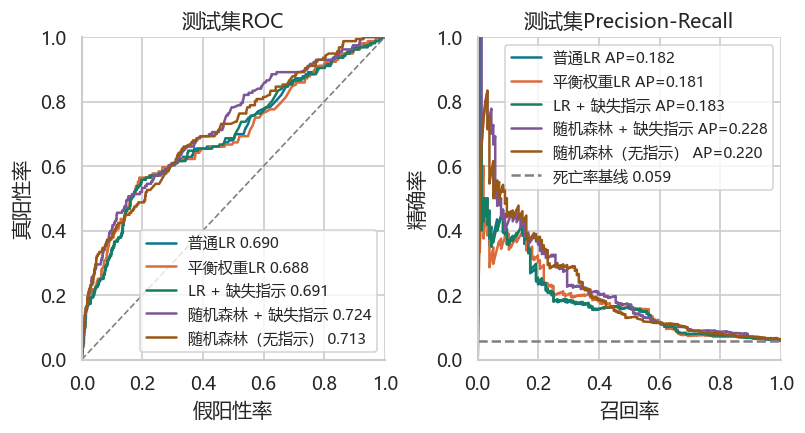

In [9]:
def evaluate(yt, probability, threshold):
    yt, probability = np.asarray(yt), np.asarray(probability)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, prediction, labels=[0, 1]).ravel()
    return {"AUROC": roc_auc_score(yt, probability), "AP": average_precision_score(yt, probability), "Brier": brier_score_loss(yt, probability), "accuracy": accuracy_score(yt, prediction), "balanced_accuracy": balanced_accuracy_score(yt, prediction), "sensitivity": tp/(tp+fn), "specificity": tn/(tn+fp), "PPV": tp/(tp+fp) if tp+fp else 0.0, "NPV": tn/(tn+fn) if tn+fn else 0.0, "F1": f1_score(yt, prediction, zero_division=0), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

test_probabilities = {name: model.predict_proba(X_test)[:, 1] for name, model in fitted.items()}
metric_rows = []
for name, probability in test_probabilities.items():
    for setting, cutoff in [("default_0.5", .5), ("train_OOF_sens80", thresholds[name])]:
        metric_rows.append({"model": name, "threshold_rule": setting, "threshold": cutoff, **evaluate(y_test, probability, cutoff)})
metrics = pd.DataFrame(metric_rows)
display(save_table(metrics, "test_metrics"))

bootstrap_metrics = ["AUROC", "AP", "Brier", "sensitivity", "specificity", "PPV", "F1"]
rng = np.random.RandomState(SEED)
test_y = y_test.to_numpy()
positive_positions, negative_positions = np.flatnonzero(test_y == 1), np.flatnonzero(test_y == 0)
boot = {name: [] for name in fitted}
for b in range(1000):
    positions = np.concatenate([rng.choice(positive_positions, len(positive_positions), replace=True), rng.choice(negative_positions, len(negative_positions), replace=True)])
    for name, probability in test_probabilities.items():
        boot[name].append(evaluate(test_y[positions], probability[positions], thresholds[name]))
ci_rows = []
for name in fitted:
    point = evaluate(test_y, test_probabilities[name], thresholds[name])
    for metric in bootstrap_metrics:
        samples = [row[metric] for row in boot[name]]
        ci_rows.append({"model": name, "metric": metric, "estimate": point[metric], "CI_low": np.percentile(samples, 2.5), "CI_high": np.percentile(samples, 97.5)})
confidence_intervals = pd.DataFrame(ci_rows)
display(save_table(confidence_intervals, "test_bootstrap_CI"))
delta_rows = []
for other in [name for name in fitted if name != best_name]:
    for metric in ["AUROC", "AP", "Brier"]:
        delta = np.array([row[metric] for row in boot[best_name]]) - np.array([row[metric] for row in boot[other]])
        estimates = confidence_intervals.set_index(["model", "metric"]).estimate
        delta_rows.append({"reference": best_name, "comparison": other, "metric": metric, "estimate": estimates[best_name, metric] - estimates[other, metric], "delta_mean_bootstrap": delta.mean(), "CI_low": np.percentile(delta, 2.5), "CI_high": np.percentile(delta, 97.5)})
save_table(pd.DataFrame(delta_rows), "paired_bootstrap_differences")

fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.5), constrained_layout=True)
for (name, probability), color in zip(test_probabilities.items(), COLORS):
    if name == "Dummy": continue
    fpr, tpr, _ = roc_curve(y_test, probability)
    pr, re, _ = precision_recall_curve(y_test, probability)
    axes[0].plot(fpr, tpr, color=color, label=f"{SHORT[name]} {roc_auc_score(y_test, probability):.3f}")
    axes[1].plot(re, pr, color=color, label=f"{SHORT[name]} AP={average_precision_score(y_test, probability):.3f}")
axes[0].plot([0, 1], [0, 1], ls="--", color="gray", lw=1)
axes[1].axhline(y_test.mean(), color="gray", ls="--", label=f"死亡率基线 {y_test.mean():.3f}")
axes[0].set(title="测试集ROC", xlabel="假阳性率", ylabel="真阳性率", xlim=(0, 1), ylim=(0, 1))
axes[1].set(title="测试集Precision-Recall", xlabel="召回率", ylabel="精确率", xlim=(0, 1), ylim=(0, 1))
for ax in axes: ax.legend(fontsize=9)
show_figure("06_ROC_PR")

## 9. 校准、混淆矩阵与工作点
校准曲线只评估，不用测试标签修正概率。
对数几率校准回归给出截距、斜率，理想值分别是0、1。
类别权重可能提高少数类召回，但并不保证概率准确。

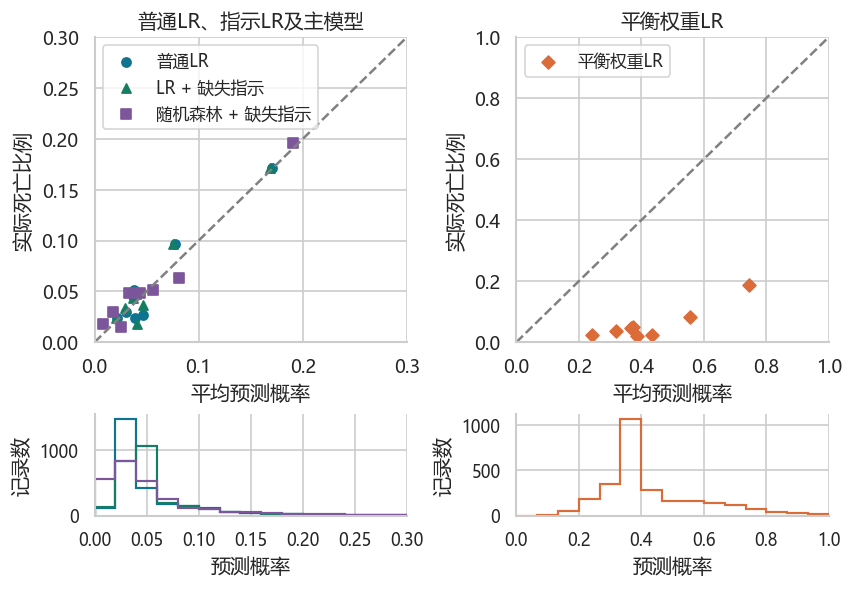

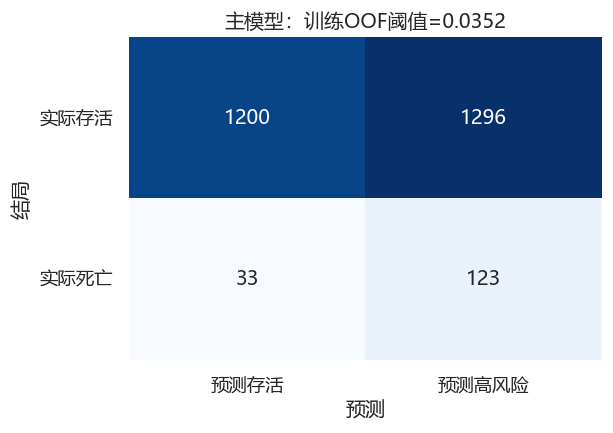

,model,calibration_intercept,intercept_low,intercept_high,calibration_slope,slope_low,slope_high,Brier
0,LR,-0.003553,-0.518819,0.511712,0.988294,0.799090,1.177499,0.052263
1,LR_balanced,-2.735776,-2.905753,-2.565799,0.838841,0.675651,1.002032,0.199183
2,LR_missing,0.005063,-0.515131,0.525257,0.990365,0.799638,1.181092,0.052250
3,RF_missing,-0.132005,-0.580825,0.316815,0.931023,0.762916,1.099130,0.050939


In [10]:
calibration_rows, calibration_bins = [], []
fig, calibration_axes = plt.subplots(2, 2, figsize=(7, 4.8), height_ratios=[3, 1], layout="constrained")
axes = calibration_axes[0]
for (name, probability), color in zip(test_probabilities.items(), COLORS):
    if name in {"Dummy", "RF_plain"}: continue
    panel = int(name == "LR_balanced")
    bins = pd.qcut(probability, 8, labels=False, duplicates="drop")
    grouped = pd.DataFrame({"bin": bins, "probability": probability, "outcome": test_y}).groupby("bin", observed=True).agg(n=("outcome", "size"), deaths=("outcome", "sum"), predicted=("probability", "mean"), observed=("outcome", "mean")).reset_index()
    calibration_bins.extend([{"model": name, **row} for row in grouped.to_dict("records")])
    axes[panel].scatter(grouped.predicted, grouped.observed, color=color, label=SHORT[name], s=30, marker={"LR":"o", "LR_missing":"^", "RF_missing":"s", "LR_balanced":"D"}[name])
    calibration_axes[1, panel].hist(probability, bins=np.linspace(0, [.3, 1][panel], 16), histtype="step", color=color, linewidth=1.3)
    lp = logit(np.clip(probability, 1e-6, 1-1e-6))
    cf = sm.GLM(test_y, sm.add_constant(lp), family=sm.families.Binomial()).fit()
    ci = cf.conf_int()
    calibration_rows.append({"model": name, "calibration_intercept": cf.params[0], "intercept_low": ci[0, 0], "intercept_high": ci[0, 1], "calibration_slope": cf.params[1], "slope_low": ci[1, 0], "slope_high": ci[1, 1], "Brier": brier_score_loss(y_test, probability)})
for ax, limit, title in zip(axes, [.3, 1], ["普通LR、指示LR及主模型", "平衡权重LR"]):
    ax.plot([0, limit], [0, limit], "--", color="gray")
    ax.set(title=title, xlabel="平均预测概率", ylabel="实际死亡比例", xlim=(0, limit), ylim=(0, limit))
    ax.legend(fontsize=10, loc="upper left")
for ax, limit in zip(calibration_axes[1], [.3, 1]):
    ax.set(xlim=(0, limit), xlabel="预测概率", ylabel="记录数")
    ax.tick_params(labelsize=10)
show_figure("07_calibration_split")
save_table(pd.DataFrame(calibration_bins), "calibration_bins")
fig, ax = plt.subplots(figsize=(5, 3.5), layout="constrained")
main_probability = test_probabilities[best_name]
main_threshold = thresholds[best_name]
main_cm = confusion_matrix(y_test, main_probability >= main_threshold, labels=[0, 1])
sns.heatmap(main_cm, annot=True, fmt="d", cbar=False, cmap="Blues", ax=ax, xticklabels=["预测存活", "预测高风险"], yticklabels=["实际存活", "实际死亡"])
ax.set(title=f"主模型：训练OOF阈值={main_threshold:.4f}", xlabel="预测", ylabel="结局")
ax.tick_params(axis="y", rotation=0)
show_figure("07_calibration_confusion")
display(save_table(pd.DataFrame(calibration_rows), "calibration"))

## 10. 分组表现与敏感性检查
不删除重复行。报告实验室全缺失/至少一项有值的测试表现，
以及排除负年龄原始编码和超过216个月记录后的测试表现。
使用同一冻结模型；这些是评价人群变化的敏感性分析，不是重新训练后的性能。

In [11]:
subgroups = {
    "all_labs_missing": X_test[lab_columns].isna().all(axis=1).to_numpy(),
    "some_labs_observed": ~X_test[lab_columns].isna().all(axis=1).to_numpy(),
    "age_0_to_216_only": raw_data.loc[test_index, "age_month"].between(0, 216).to_numpy(),
}
subgroup_rows = []
for group, mask in subgroups.items():
    yt, pt = test_y[mask], main_probability[mask]
    subgroup_rows.append({"group": group, "model": best_name, "n": int(mask.sum()), "deaths": int(yt.sum()), "mortality": yt.mean(), **evaluate(yt, pt, main_threshold)})
display(save_table(pd.DataFrame(subgroup_rows), "subgroup_sensitivity"))
mask = subgroups["all_labs_missing"]
yt, pt = test_y[mask], main_probability[mask]
rng_group = np.random.RandomState(SEED)
strata = [np.flatnonzero(yt == label) for label in [0, 1]]
group_indices = [np.concatenate([rng_group.choice(s, len(s), replace=True) for s in strata]) for _ in range(1000)]
group_ci = []
for metric, scorer in [("AUROC", roc_auc_score), ("AP", average_precision_score)]:
    lower, upper = np.percentile([scorer(yt[i], pt[i]) for i in group_indices], [2.5, 97.5])
    group_ci.append({"metric": metric, "n": len(yt), "deaths": yt.sum(), "estimate": scorer(yt, pt), "CI_low": lower, "CI_high": upper})
save_table(pd.DataFrame(group_ci), "all_labs_missing_bootstrap_CI")

,group,model,n,deaths,mortality,AUROC,AP,Brier,accuracy,balanced_accuracy,sensitivity,specificity,PPV,NPV,F1,TN,FP,FN,TP
0,all_labs_missing,RF_missing,877,36,0.041049,0.522675,0.042986,0.039735,0.483466,0.544557,0.611111,0.478002,0.047722,0.966346,0.088531,402,439,14,22
1,some_labs_observed,RF_missing,1775,120,0.067606,0.768575,0.274833,0.056475,0.506479,0.661921,0.841667,0.482175,0.105428,0.976744,0.187384,798,857,19,101
2,age_0_to_216_only,RF_missing,2635,155,0.058824,0.726155,0.230364,0.050845,0.499431,0.634274,0.787097,0.481452,0.086648,0.973105,0.156110,1194,1286,33,122


,metric,n,deaths,estimate,CI_low,CI_high
0,AUROC,877,36,0.522675,0.427398,0.607401
1,AP,877,36,0.042986,0.035980,0.056431


## 11. 简化前向特征选择（补充实验）
六变量范围内的逐步选择，不能称为复现原论文397特征集成方法。
外层3折评价，内层3折逐步加入使AP最高的特征，再按内层AP选择特征数量。
每次候选模型均重新在Pipeline内拟合插补和标准化。
最终在全部训练集重复选择并在测试集评价一次；不参与主模型选择。

,fold,k,features,outer_AP,outer_AUROC
0,1,4,"lab_5237_min, lab_5225_range, lab_5257_min, ag...",0.162292,0.711265
1,2,6,"lab_5237_min, lab_5257_min, lab_5225_range, ag...",0.199628,0.716944
2,3,5,"lab_5237_min, lab_5257_min, lab_5225_range, la...",0.189228,0.714774


,model,k,features,AUROC,AP,Brier,accuracy,balanced_accuracy,sensitivity,specificity,PPV,NPV,F1,TN,FP,FN,TP
0,LR_forward_selected,6,"lab_5237_min, lab_5257_min, lab_5225_range, ag...",0.689828,0.182289,0.052263,0.940799,0.508814,0.019231,0.998397,0.428571,0.942155,0.03681,2492,4,153,3


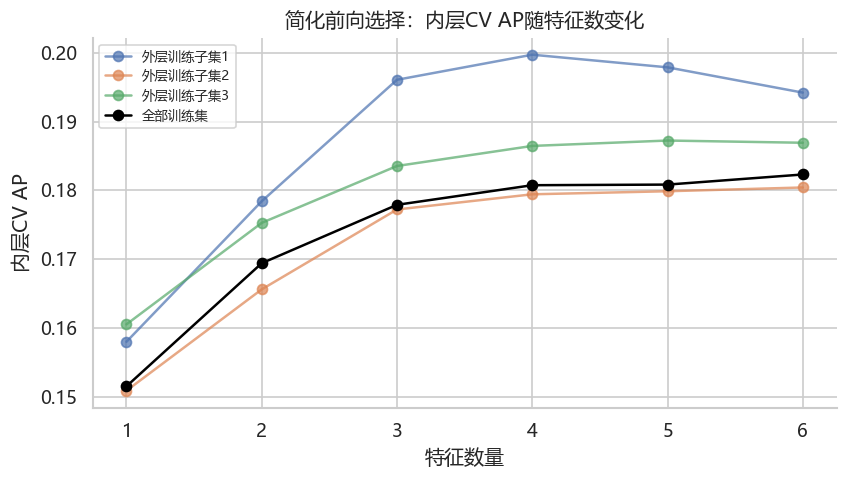

In [12]:
def forward_select(x, yt, seed=42):
    inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    chosen, path = [], []
    while len(chosen) < len(FEATURES):
        candidates = []
        for feature in FEATURES:
            if feature in chosen: continue
            cols = chosen + [feature]
            score = cross_val_score(lr_pipeline(), x[cols], yt, cv=inner_cv, scoring="average_precision", n_jobs=1, error_score="raise").mean()
            candidates.append((score, feature))
        score, feature = max(candidates, key=lambda item: item[0])
        chosen.append(feature)
        path.append({"k": len(chosen), "features": chosen.copy(), "inner_CV_AP": float(score)})
    best = max(path, key=lambda item: item["inner_CV_AP"])
    return best["features"], path

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED+10)
selection_outer, selection_path = [], []
for fold, (itr, iva) in enumerate(outer_cv.split(X_train, y_train), 1):
    cols, path = forward_select(X_train.iloc[itr], y_train.iloc[itr], SEED+fold)
    selected_model = lr_pipeline().fit(X_train.iloc[itr][cols], y_train.iloc[itr])
    validation_p = selected_model.predict_proba(X_train.iloc[iva][cols])[:, 1]
    selection_outer.append({"fold": fold, "k": len(cols), "features": ", ".join(cols), "outer_AP": average_precision_score(y_train.iloc[iva], validation_p), "outer_AUROC": roc_auc_score(y_train.iloc[iva], validation_p)})
    selection_path.extend([{**p, "features": ", ".join(p["features"]), "outer_fold": fold} for p in path])
selected_columns, final_selection_path = forward_select(X_train, y_train, SEED)
selected_model = lr_pipeline().fit(X_train[selected_columns], y_train)
selected_probability = selected_model.predict_proba(X_test[selected_columns])[:, 1]
selection_test = {"model": "LR_forward_selected", "k": len(selected_columns), "features": ", ".join(selected_columns), **evaluate(y_test, selected_probability, .5)}
display(save_table(pd.DataFrame(selection_outer), "feature_selection_outer_CV"))
save_table(pd.DataFrame(selection_path), "feature_selection_paths")
save_table(pd.DataFrame([{**p, "features": ", ".join(p["features"])} for p in final_selection_path]), "feature_selection_final_path")
display(save_table(pd.DataFrame([selection_test]), "feature_selection_test"))
fig, ax = plt.subplots(figsize=(8, 4))
for fold in range(1, 4):
    rows = [r for r in selection_path if r["outer_fold"] == fold]
    ax.plot([r["k"] for r in rows], [r["inner_CV_AP"] for r in rows], "o-", alpha=.7, label=f"外层训练子集{fold}")
ax.plot([r["k"] for r in final_selection_path], [r["inner_CV_AP"] for r in final_selection_path], "o-", color="black", label="全部训练集")
ax.set(title="简化前向选择：内层CV AP随特征数变化", xlabel="特征数量", ylabel="内层CV AP", xticks=range(1, 7))
ax.legend(fontsize=8)
show_figure("08_feature_selection")

## 12. 参考模型系数与SHAP
SHAP解释教师参考的平衡LR，背景样本来自训练集，测试样本只用于解释。
线性模型的SHAP贡献在log-odds空间，不是概率百分点。
蜂群图中的颜色是插补和标准化后的变量取值。

,feature,coefficient_standardized
0,age_month,0.057297
1,lab_5237_min,-0.268450
2,lab_5227_min,0.159608
3,lab_5225_range,0.146506
4,lab_5235_max,0.152612
5,lab_5257_min,-0.464922


C:\Users\Lenovo\Documents\Codex\2026-10-29\dui\work\pic-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,mean_abs_SHAP_log_odds
5,lab_5257_min,0.336807
1,lab_5237_min,0.170723
2,lab_5227_min,0.097313
4,lab_5235_max,0.095726
3,lab_5225_range,0.091316
0,age_month,0.043386


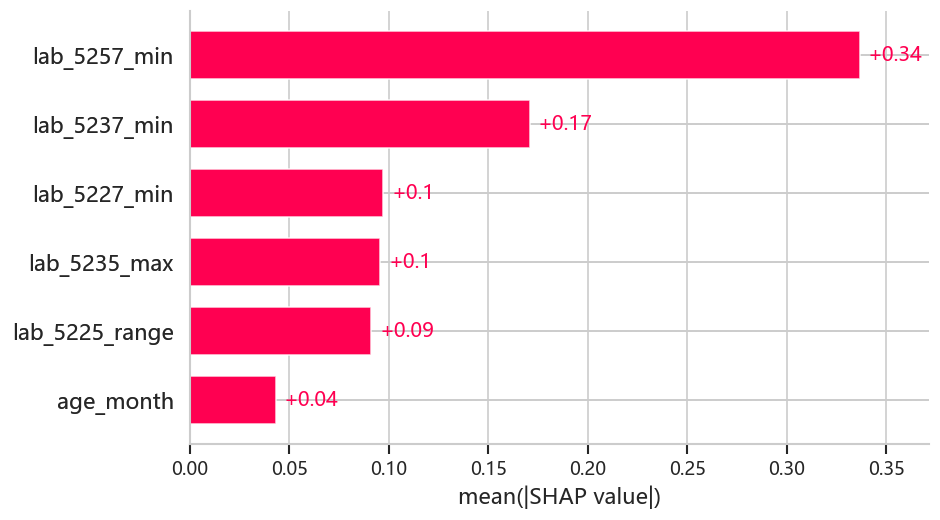

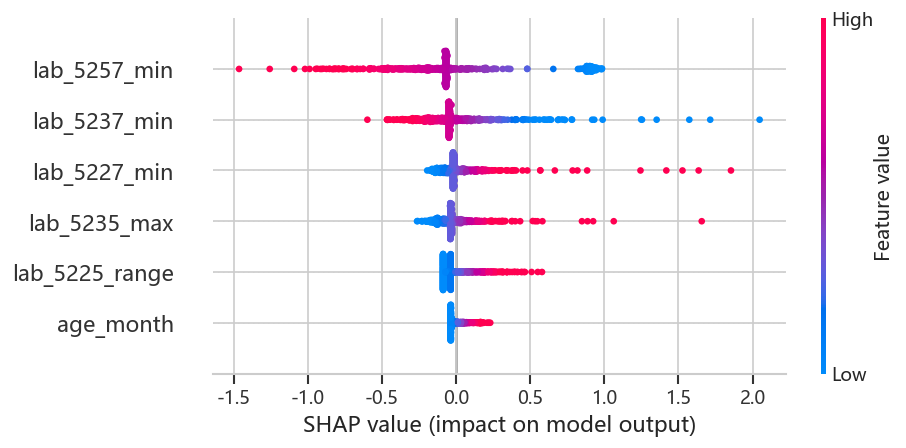

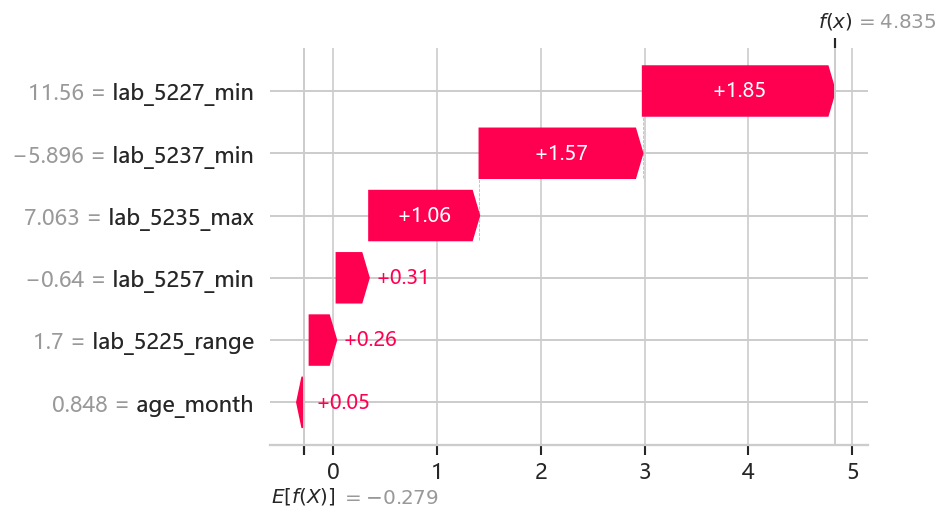

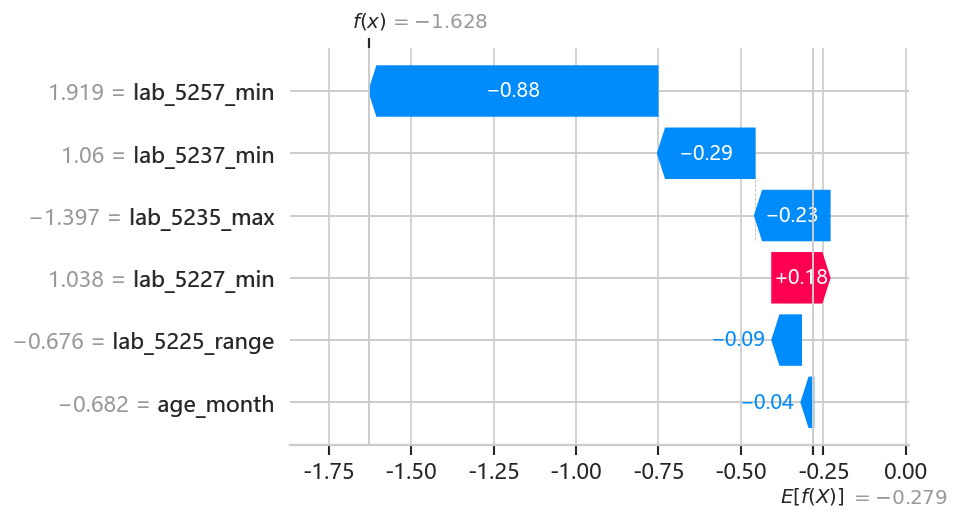

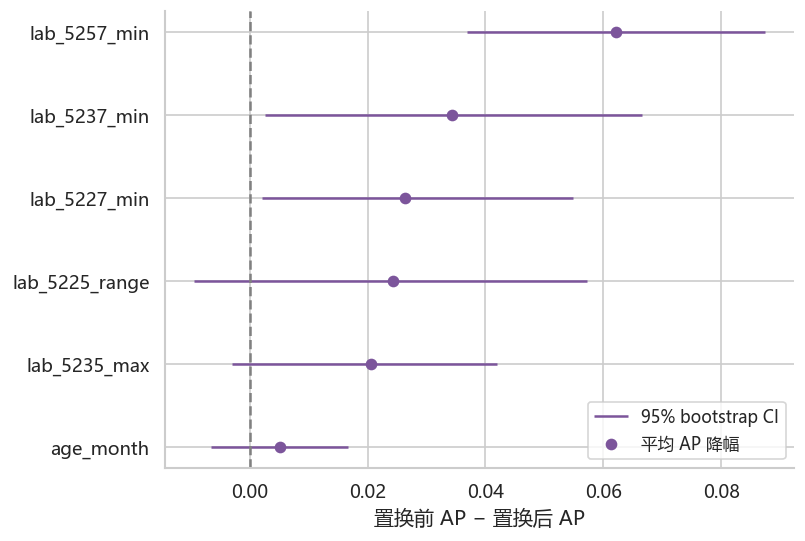

In [13]:
reference_model = fitted["LR_balanced"]
classifier = reference_model.named_steps["classifier"]
coefficient_table = pd.DataFrame({"feature": FEATURES, "coefficient_standardized": classifier.coef_[0]})
display(save_table(coefficient_table, "reference_LR_coefficients"))
import shap
processed_train = pd.DataFrame(reference_model[:-1].transform(X_train), columns=FEATURES, index=X_train.index)
processed_test = pd.DataFrame(reference_model[:-1].transform(X_test), columns=FEATURES, index=X_test.index)
background = shap.sample(processed_train, 200, random_state=SEED)
X_shap = processed_test.iloc[:500]
explainer = shap.LinearExplainer(classifier, background)
shap_values = explainer(X_shap)
assert np.allclose(shap_values.base_values + shap_values.values.sum(axis=1), classifier.decision_function(X_shap.to_numpy()))
shap_importance = pd.DataFrame({"feature": FEATURES, "mean_abs_SHAP_log_odds": np.abs(shap_values.values).mean(axis=0)}).sort_values("mean_abs_SHAP_log_odds", ascending=False)
display(save_table(shap_importance, "reference_SHAP_importance"))
shap.plots.bar(shap_values, max_display=6, show=False)
plt.tight_layout()
show_figure("09_SHAP_bar")
shap.plots.beeswarm(shap_values, max_display=6, show=False)
plt.tight_layout()
show_figure("10_SHAP_beeswarm")
for label, pos in [("high", int(np.argmax(test_probabilities["LR_balanced"][:500]))), ("low", int(np.argmin(test_probabilities["LR_balanced"][:500])))]:
    shap.plots.waterfall(shap_values[pos], max_display=6, show=False)
    plt.tight_layout()
    show_figure(f"11_SHAP_{label}")

rf = fitted[best_name]
rng_importance = np.random.RandomState(SEED)
orders = [rng_importance.permutation(len(X_test)) for _ in range(10)]
indices = [np.concatenate([rng_importance.choice(positive_positions, len(positive_positions), replace=True),
                           rng_importance.choice(negative_positions, len(negative_positions), replace=True)]) for _ in range(1000)]
baseline_ap = np.array([average_precision_score(test_y[i], main_probability[i]) for i in indices])
importance_rows = []
for feature in FEATURES:
    permuted_scores = []
    for order in orders:
        permuted = X_test.copy()
        # Permute the raw column, including NaNs, so its indicator follows the value.
        permuted[feature] = X_test[feature].to_numpy()[order]
        permuted_scores.append(rf.predict_proba(permuted)[:, 1])
    estimate = average_precision_score(test_y, main_probability) - np.mean([average_precision_score(test_y, p) for p in permuted_scores])
    deltas = [ap - np.mean([average_precision_score(test_y[i], p[i]) for p in permuted_scores]) for i, ap in zip(indices, baseline_ap)]
    low, high = np.percentile(deltas, [2.5, 97.5])
    importance_rows.append({"feature": feature, "estimate": estimate, "CI_low": low, "CI_high": high,
                            "permutations": len(orders), "bootstrap_repeats": len(indices), "n": len(test_y)})
rf_importance = pd.DataFrame(importance_rows).sort_values("estimate", ascending=False)
save_table(rf_importance, "RF_permutation_importance")
fig, ax = plt.subplots(figsize=(6.6, 4.4), layout="constrained")
ordered = rf_importance.iloc[::-1]
ypos = np.arange(len(ordered))
ax.hlines(ypos, ordered.CI_low, ordered.CI_high, color=COLORS[4], label="95% bootstrap CI")
ax.scatter(ordered.estimate, ypos, color=COLORS[4], label="平均 AP 降幅")
ax.set_yticks(ypos, labels=ordered.feature)
ax.axvline(0, color="gray", ls="--")
ax.legend(fontsize=10)
ax.set(xlabel="置换前 AP − 置换后 AP")
show_figure("13_RF_permutation")

## 13. 保存、复现与研究边界
保存完整Pipeline、软件版本、分割索引、模型指标和原始预测。
results/内逐行预测只供本地复核，网页发布目录不包含这些数据。
教学Excel无ID；上游聚合CSV可用于患者分组，但没有原始事件表以复核采集窗口。

In [14]:
for name, model in fitted.items():
    joblib.dump(model, ROOT / "models" / f"{name}.joblib")
joblib.dump(selected_model, ROOT / "models" / "LR_forward_selected.joblib")
prediction_output = pd.DataFrame({"source_row_index": test_index, "true_label": test_y})
for name, probability in test_probabilities.items():
    prediction_output[f"{name}_probability"] = probability
prediction_output.to_csv(ROOT / "results" / "test_predictions_private.csv", index=False, encoding="utf-8-sig")
result = {
    "audit": audit, "data_sha256": data_sha256, "seed": SEED, "python_version": platform.python_version(), "versions": versions,
    "primary_model_selected_by_train_CV_AP": best_name, "thresholds": thresholds,
    "selected_columns_supplementary": selected_columns,
    "CV_results": cv_results.to_dict(orient="records"),
    "test_metrics": metrics.to_dict(orient="records"),
    "test_CI": confidence_intervals.to_dict(orient="records"),
    "limitations": ["原记录级划分可能患者跨集；扩展分析按上游ID核对并分组验证", "无原始事件时间，无法核验24小时窗口", "实验室变量名称和单位未知", "上游六特征筛选来源未知", "全样本统计仅探索描述，完整病例推断受选择偏倚影响", "固定模型区间不含重新训练与调参不确定性", "缺少外部验证"],
}
(ROOT / "results" / "summary.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
(ROOT / "requirements.txt").write_text("\n".join(f"{name}=={version}" for name, version in versions.items())+"\n", encoding="utf-8")
print("主模型:", best_name, "阈值:", thresholds[best_name])
display(metrics[metrics.threshold_rule == "train_OOF_sens80"])
print("完成：tables/、figures/、models/、results/。")

主模型: RF_missing 阈值: 0.035158551417482115


,model,threshold_rule,threshold,AUROC,AP,Brier,accuracy,balanced_accuracy,sensitivity,specificity,PPV,NPV,F1,TN,FP,FN,TP
1,Dummy,train_OOF_sens80,0.500000,0.500000,0.058824,0.055363,0.941176,0.500000,0.000000,1.000000,0.000000,0.941176,0.000000,2496,0,156,0
3,LR,train_OOF_sens80,0.038157,0.689828,0.182289,0.052263,0.506410,0.596554,0.698718,0.494391,0.079504,0.963310,0.142764,1234,1262,47,109
5,LR_balanced,train_OOF_sens80,0.376506,0.688272,0.181080,0.199183,0.508296,0.585537,0.673077,0.497997,0.077320,0.960587,0.138705,1243,1253,51,105
7,LR_missing,train_OOF_sens80,0.040051,0.690781,0.183367,0.052250,0.430995,0.586538,0.762821,0.410256,0.074796,0.965127,0.136234,1024,1472,37,119
9,RF_missing,train_OOF_sens80,0.035159,0.724494,0.227510,0.050939,0.498869,0.634615,0.788462,0.480769,0.086681,0.973236,0.156190,1200,1296,33,123
11,RF_plain,train_OOF_sens80,0.033063,0.713065,0.219695,0.051099,0.493213,0.619591,0.762821,0.476362,0.083450,0.969821,0.150442,1189,1307,37,119


完成：tables/、figures/、models/、results/。


## 14. 课堂补充练习与更严格的验证
原主分析保留以便核对。补充均值插补、分数分布、普通LR公式、等预算搜索、
官方划分与患者分组验证，以及仅在原训练集进行的重复嵌套交叉验证。
患者元数据映射以原行序保持为前提，逐行核对所保留的七列后才使用。

Extended: mean/median completed


Extended: matched-budget CV completed


Extended: official_seed0 completed


Extended: patient_group completed


Extended: nested outer fold 1 /10


Extended: nested outer fold 2 /10


... (15 outputs left out)

validation_sensitivity_metrics


,protocol,model,AUROC,AP,Brier,sensitivity,specificity,accuracy,FP,FN,threshold,parameters
0,official_seed0,LR,0.731062,0.172017,0.050894,0.846667,0.355715,0.383484,1612,23,0.040252,"{""classifier__C"": 0.01, ""classifier__class_wei..."
1,official_seed0,RF_plain,0.752662,0.207053,0.049447,0.826667,0.451639,0.472851,1372,26,0.039921,"{""classifier__bootstrap"": true, ""classifier__c..."
2,official_seed0,RF_missing,0.749903,0.198339,0.049479,0.826667,0.474420,0.494344,1315,26,0.040050,"{""classifier__bootstrap"": true, ""classifier__c..."
3,patient_group,LR,0.715431,0.181053,0.054521,0.858025,0.367257,0.397281,1573,23,0.037998,"{""classifier__C"": 0.1, ""classifier__class_weig..."
4,patient_group,RF_plain,0.734911,0.195709,0.053816,0.796296,0.479083,0.498489,1295,33,0.036479,"{""classifier__bootstrap"": true, ""classifier__c..."
5,patient_group,RF_missing,0.732509,0.197297,0.053676,0.777778,0.514481,0.530589,1207,36,0.037964,"{""classifier__bootstrap"": true, ""classifier__c..."


repeated_nested_CV_summary


,model,metric,mean,SD_across_outer_folds,min,max,n_outer_folds,outer_repeats,inner_folds
0,LR,AUROC,0.717123,0.038238,0.670158,0.783465,10,2,3
1,LR,AP,0.189486,0.025266,0.143191,0.224944,10,2,3
2,LR,Brier,0.052333,0.000909,0.050891,0.053876,10,2,3
3,RF_plain,AUROC,0.733982,0.033206,0.685014,0.782142,10,2,3
4,RF_plain,AP,0.219544,0.035646,0.149116,0.262288,10,2,3
5,RF_plain,Brier,0.051301,0.001272,0.049440,0.054238,10,2,3
6,RF_missing,AUROC,0.735507,0.032031,0.697000,0.783219,10,2,3
7,RF_missing,AP,0.217682,0.035294,0.153114,0.271774,10,2,3
8,RF_missing,Brier,0.051464,0.001045,0.049694,0.053631,10,2,3


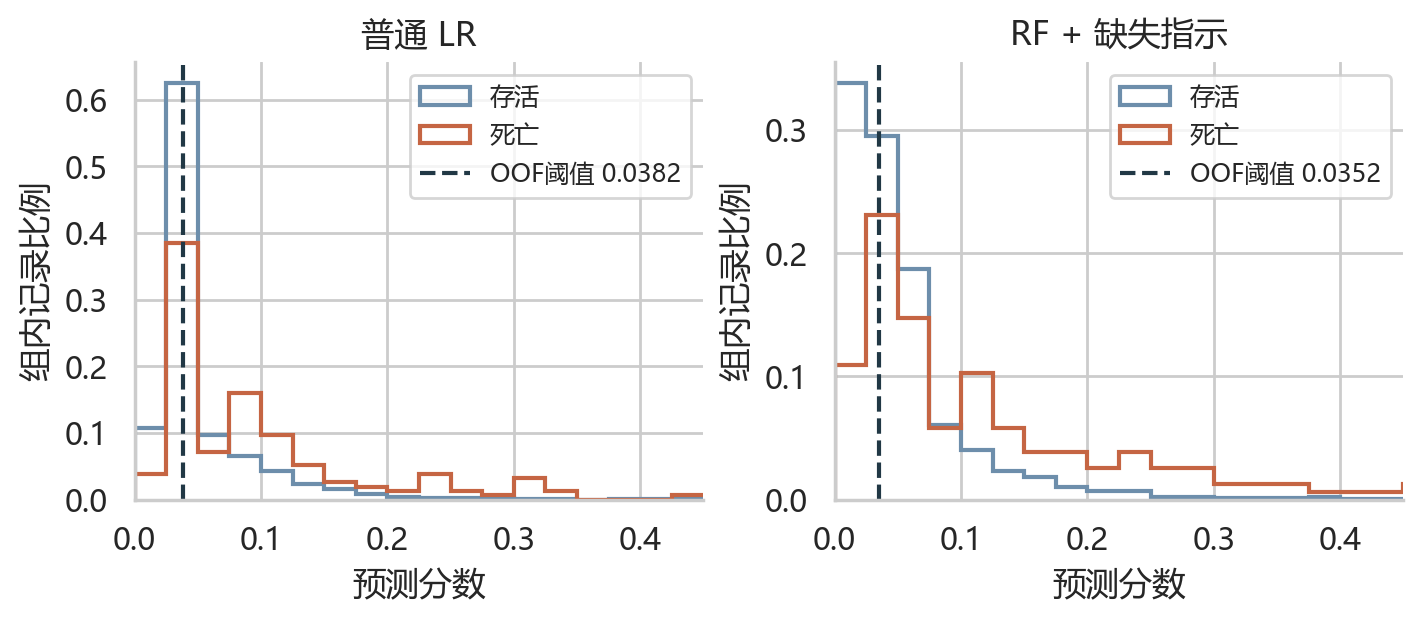

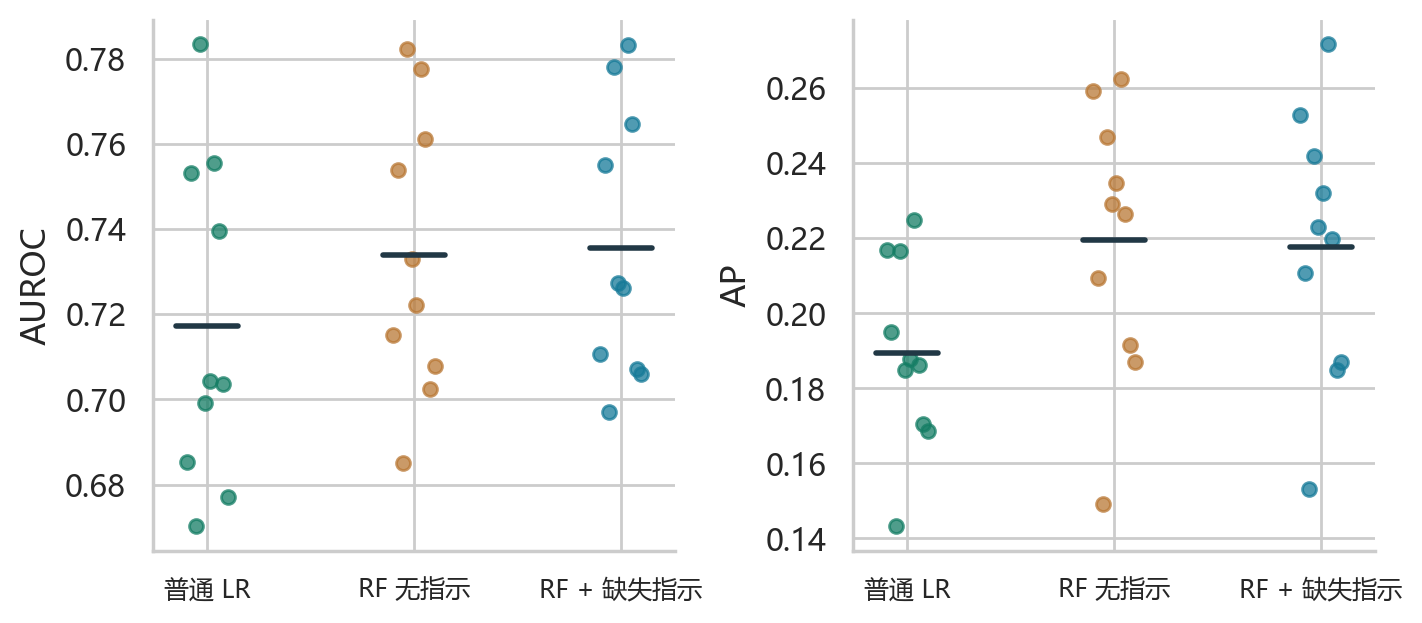

In [15]:
from extended_analysis import run as run_extended_analysis
run_extended_analysis()
for table_name in ["imputation_sensitivity", "matched_budget_CV", "validation_protocols",
                   "validation_sensitivity_metrics", "repeated_nested_CV_summary"]:
    print(table_name)
    display(pd.read_csv(ROOT / "tables" / f"{table_name}.csv"))
if NOTEBOOK_MODE:
    from IPython.display import Image
    for stem in ["14_score_distribution", "15_repeated_nested_CV"]:
        display(Image(filename=str(ROOT / "figures" / f"{stem}.png")))